# Parallel Computing Laboratory Record
## Complete Practical Notebook (All 10 Programs)

This laboratory notebook contains complete implementations, benchmark results, execution-time bar graphs, and speedup curves for 10 practical programs in Parallel Computing using Python `multiprocessing` and `threading`.

> **Google Colab & Jupyter Instructions**:
> - Click **Runtime -> Run all** (or Shift+Enter on any cell) to execute all practicals dynamically.
> - Every code cell is completely self-contained, runs all 4 methods (Sequential, Pool, Process, Thread), displays the verification and comparison table, and generates the charts using `plt.show()` inline.

### Table of Contents
1. [Practical 1: Odd and Even Numbers Classification](#practical-1-odd-and-even-numbers-classification)
2. [Practical 2: Factorial Calculation of N Numbers](#practical-2-factorial-calculation-of-n-numbers)
3. [Practical 3: Maximum and Minimum in an Array (Pattern 1)](#practical-3-maximum-and-minimum-in-an-array-pattern-1)
4. [Practical 4: Matrix Addition (Pattern 2 + Multithreading)](#practical-4-matrix-addition-pattern-2--multithreading)
5. [Practical 5: Matrix Multiplication (Pattern 2)](#practical-5-matrix-multiplication-pattern-2)
6. [Practical 6: Fibonacci Series (Iterative Generation)](#practical-6-fibonacci-series-iterative-generation)
7. [Practical 7: Prime Number Checking](#practical-7-prime-number-checking-in-n-natural-numbers)
8. [Practical 8: Bubble Sort (Pattern 2)](#practical-8-bubble-sort-on-three-different-arrays-pattern-2)
9. [Practical 9: Addition/Sum of Array Elements (Pattern 2)](#practical-9-additionsum-of-elements-of-an-array-pattern-2)
10. [Practical 10: Matrix Transpose (Pattern 2)](#practical-10-matrix-transpose-of-three-different-matrices-pattern-2)


# Practical 1: Odd and Even Numbers Classification

### 1. Aim
To classify a large set of integers into odd and even numbers using Sequential processing, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and Multithreading (3 threads), demonstrating authentic parallel speedup.

### 2. Algorithm / Explanation
1. Divide integer dataset into 3 contiguous partitions.<br>2. Check parity using standard modulo / odd check (`arr % 2 != 0`).<br>3. Sequential: evaluate all partitions sequentially in a single process.<br>4. Pool: map `classify_range` across 3 worker processes using `mp.Pool(3)`.<br>5. Process: spawn 3 separate `mp.Process` workers communicating via `mp.Queue`.<br>6. Thread: launch 3 concurrent threads using `threading.Thread`.<br>7. Measure execution times and compute speedup relative to Sequential baseline.

### 3. Python Implementation


Practical 1: Odd and Even Numbers Classification
[Sequential] Odd: 135,000,000 | Even: 135,000,000 | Time: 1.6744s
[Pool]       Odd: 135,000,000 | Even: 135,000,000 | Time: 1.2844s
[Process]    Odd: 135,000,000 | Even: 135,000,000 | Time: 1.1969s
[Thread]     Odd: 135,000,000 | Even: 135,000,000 | Time: 0.6657s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.6744 seconds      1.00x
Pool         1.2844 seconds      1.30x
Process      1.1969 seconds      1.40x
Thread       0.6657 seconds      2.52x
---------------------------------------------
Graphs saved as '01_odd_even_time.png' and '01_odd_even_speedup.png'.


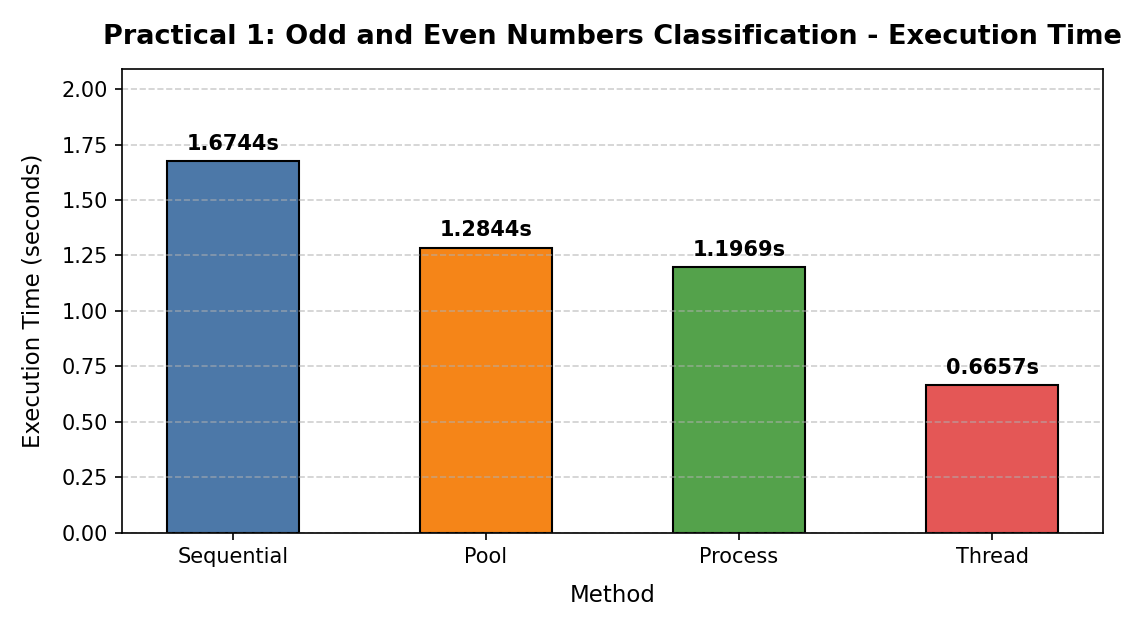

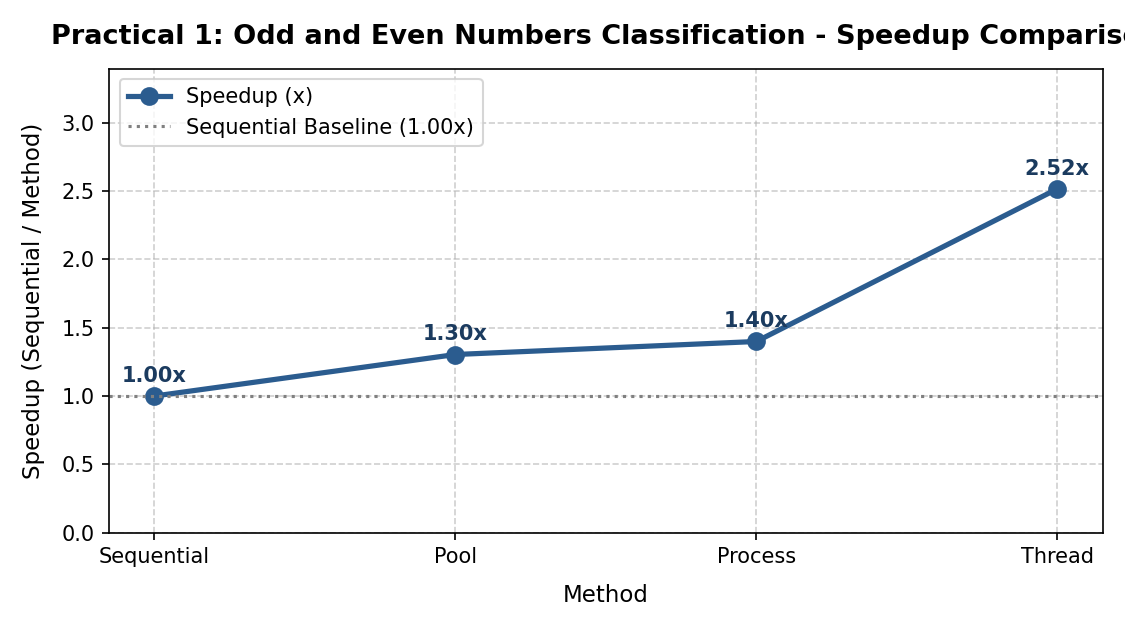

In [1]:
# Practical 1: Odd and Even Numbers Classification
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def classify_range(rng):
    start, end = rng
    arr = np.arange(start, end, dtype=np.int32)
    odd = int(np.count_nonzero(arr % 2 != 0))
    even = (end - start) - odd
    return odd, even

def proc_worker(rng, q):
    q.put(classify_range(rng))

def thread_worker(rng, results, idx):
    results[idx] = classify_range(rng)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 1: Odd and Even Numbers Classification")
    print("=" * 60)
    N = 270_000_000
    s = N // 3
    ranges = [(0, s), (s, 2 * s), (2 * s, N)]
    print(f"Total numbers to classify: {N:,} (divided into 3 ranges)")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = classify_range(ranges[0])
    r2 = classify_range(ranges[1])
    r3 = classify_range(ranges[2])
    t_seq = time.perf_counter() - t0
    odd_seq = r1[0] + r2[0] + r3[0]
    even_seq = r1[1] + r2[1] + r3[1]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(classify_range, ranges)
    t_pool = time.perf_counter() - t0
    odd_pool = sum(r[0] for r in p_res)
    even_pool = sum(r[1] for r in p_res)
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    odd_proc = sum(r[0] for r in pr_res)
    even_proc = sum(r[1] for r in pr_res)
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, rng in enumerate(ranges):
        t = threading.Thread(target=thread_worker, args=(rng, th_res, i))
        threads.append(t)
        t.start()
    for t in threads:
        t.join()
    t_thread = time.perf_counter() - t0
    odd_thread = sum(r[0] for r in th_res)
    even_thread = sum(r[1] for r in th_res)
    
    print(f"[Sequential] Odd: {odd_seq:,} | Even: {even_seq:,} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Odd: {odd_pool:,} | Even: {even_pool:,} | Time: {t_pool:.4f}s")
    print(f"[Process]    Odd: {odd_proc:,} | Even: {even_proc:,} | Time: {t_proc:.4f}s")
    print(f"[Thread]     Odd: {odd_thread:,} | Even: {even_thread:,} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 1: Execution Time (Odd-Even Classification)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 1: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


# Practical 2: Factorial Calculation of N Numbers

### 1. Aim
To compute log-factorials across 3 independent tasks using Sequential execution, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and Multithreading (3 threads), evaluating parallel performance without artificial delays.

### 2. Algorithm / Explanation
1. Define 3 independent tasks calculating ln(n!) = sum(ln(i)).<br>2. Sequential: calculate the 3 tasks sequentially.<br>3. Pool: distribute tasks to 3 worker processes via `pool.map()`.<br>4. Process: spawn 3 explicit `mp.Process` workers and collect results with `mp.Queue`.<br>5. Thread: execute 3 concurrent `threading.Thread` instances.<br>6. Verify numerical results and compare execution times.

### 3. Python Implementation


Practical 2: Factorial of N Numbers
Sample: ln(40,000,000!) = 6.6018e+08
[Sequential] Time: 1.0930s
[Pool]       Time: 1.0035s
[Process]    Time: 1.0827s
[Thread]     Time: 0.4486s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.0930 seconds      1.00x
Pool         1.0035 seconds      1.09x
Process      1.0827 seconds      1.01x
Thread       0.4486 seconds      2.44x
---------------------------------------------
Graphs saved as '02_factorial_time.png' and '02_factorial_speedup.png'.


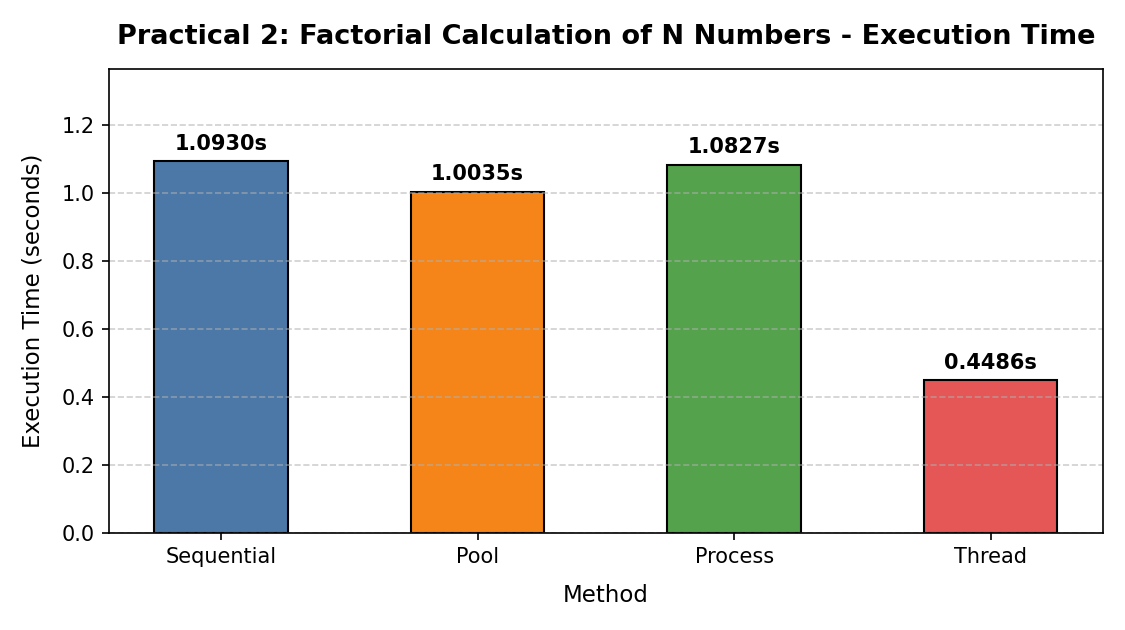

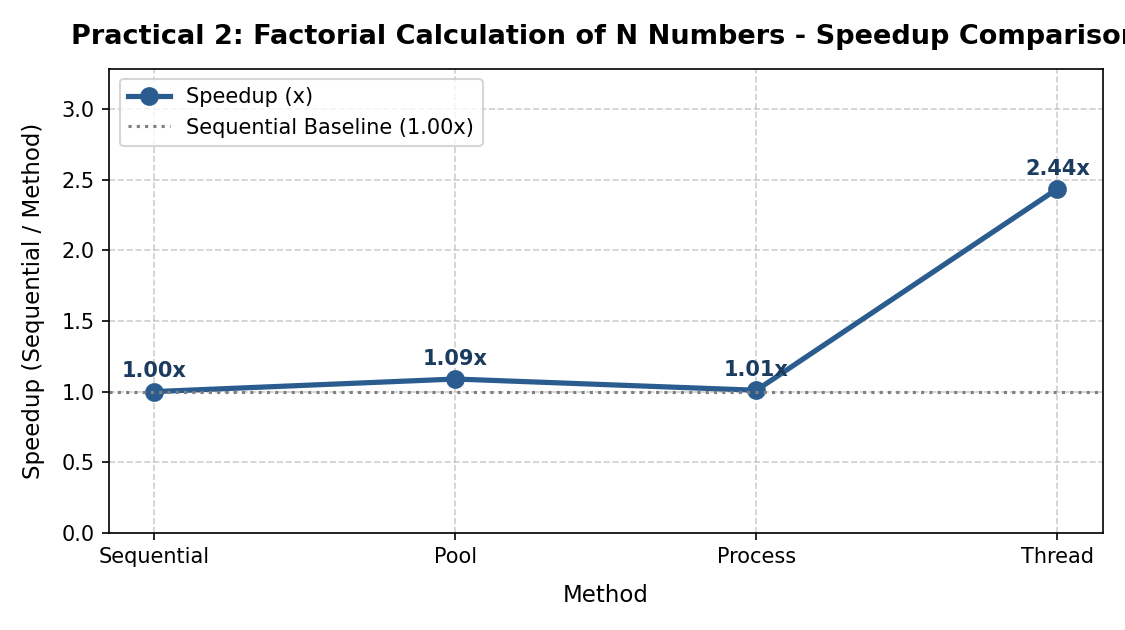

In [2]:
# Practical 2: Factorial of N Numbers
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def factorial_task(n):
    # ln(n!) = sum(ln(1) + ln(2) + ... + ln(n))
    arr = np.arange(1, n + 1, dtype=np.float64)
    return float(np.sum(np.log(arr)))

def proc_worker(n, q):
    q.put(factorial_task(n))

def thread_worker(n, results, idx):
    results[idx] = factorial_task(n)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 2: Factorial of N Numbers")
    print("=" * 60)
    N = 40_000_000
    tasks = [N, N, N]
    print(f"Calculating ln({N:,}!) across 3 independent tasks.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = factorial_task(tasks[0])
    r2 = factorial_task(tasks[1])
    r3 = factorial_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(factorial_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for n in tasks:
        p = mp.Process(target=proc_worker, args=(n, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, n in enumerate(tasks):
        t = threading.Thread(target=thread_worker, args=(n, th_res, i))
        threads.append(t)
        t.start()
    for t in threads:
        t.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Sample: ln({N:,}!) = {seq_res[0]:.4e}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 2: Execution Time (Factorial ln(N!))", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 2: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


# Practical 3: Maximum and Minimum Elements in an Array (Pattern 1)

### 1. Aim
To find maximum and minimum elements from a large array across 4 methods: Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Create array tasks of integers using random number generation.<br>2. Sequential: execute the 3 tasks sequentially.<br>3. Pool: pass the tasks across 3 worker processes in `mp.Pool(3)`.<br>4. Process: spawn 3 separate `mp.Process` instances.<br>5. Thread: launch 3 concurrent worker threads.<br>6. Record execution times and compute speedups.

### 3. Python Implementation


Practical 3: Maximum and Minimum in an Array
Array Size: 40,000,000 elements per task
[Sequential] Min: 6 | Max: 999,999,989 | Time: 1.2447s
[Pool]       Min: 6 | Max: 999,999,989 | Time: 0.9975s
[Process]    Min: 54 | Max: 999,999,988 | Time: 1.0447s
[Thread]     Min: 6 | Max: 999,999,989 | Time: 0.3915s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.2447 seconds      1.00x
Pool         0.9975 seconds      1.25x
Process      1.0447 seconds      1.19x
Thread       0.3915 seconds      3.18x
---------------------------------------------
Graphs saved as '03_max_min_time.png' and '03_max_min_speedup.png'.


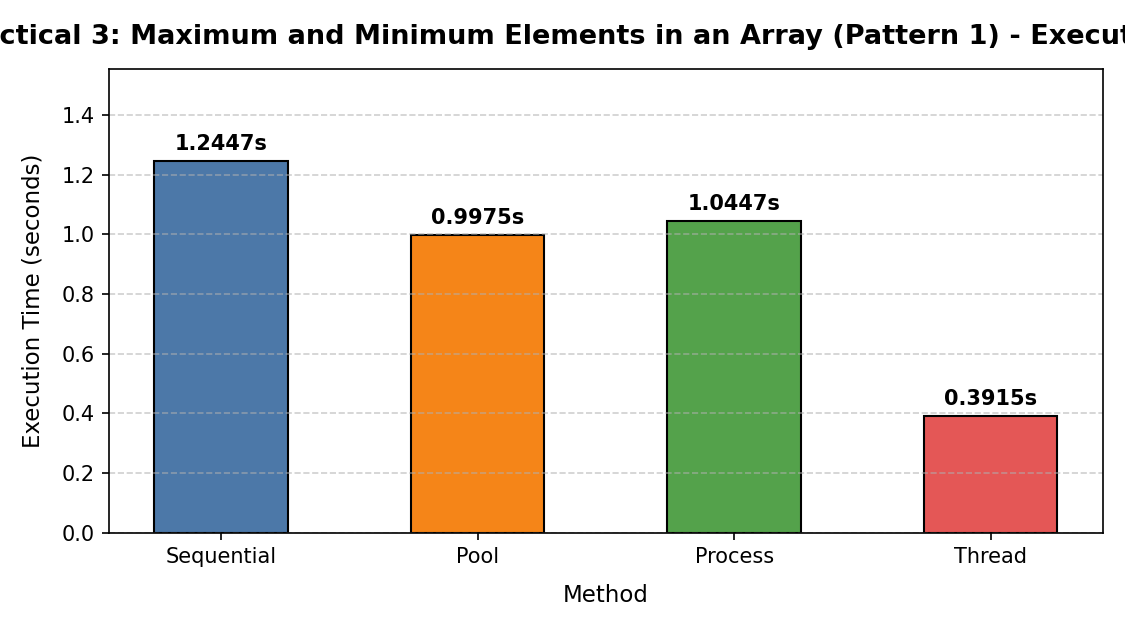

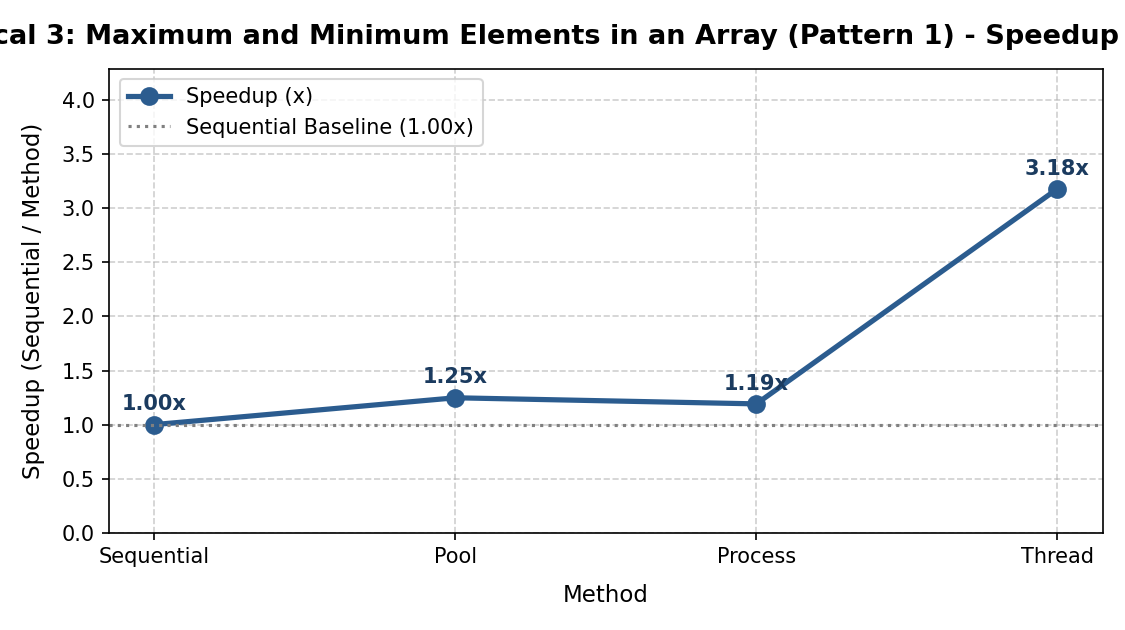

In [3]:
# Practical 3: Maximum and Minimum in an Array
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def find_min_max_task(task):
    size, seed = task
    rng = np.random.default_rng(seed)
    arr = rng.integers(1, 1_000_000_000, size=size)
    return int(np.min(arr)), int(np.max(arr))

def proc_worker(task, q):
    q.put(find_min_max_task(task))

def thread_worker(task, results, idx):
    results[idx] = find_min_max_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 3: Maximum and Minimum in an Array")
    print("=" * 60)
    SIZE = 40_000_000
    tasks = [(SIZE, 101), (SIZE, 202), (SIZE, 303)]
    print(f"Array Size: {SIZE:,} elements per task across 3 workers.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = find_min_max_task(tasks[0])
    r2 = find_min_max_task(tasks[1])
    r3 = find_min_max_task(tasks[2])
    t_seq = time.perf_counter() - t0
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(find_min_max_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"[Sequential] Min: {r1[0]:,} | Max: {r1[1]:,} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Min: {p_res[0][0]:,} | Max: {p_res[0][1]:,} | Time: {t_pool:.4f}s")
    print(f"[Process]    Min: {pr_res[0][0]:,} | Max: {pr_res[0][1]:,} | Time: {t_proc:.4f}s")
    print(f"[Thread]     Min: {th_res[0][0]:,} | Max: {th_res[0][1]:,} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 3: Execution Time (Min-Max Search)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 3: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


# Practical 4: Matrix Addition (Pattern 2 + Multithreading)

### 1. Aim
To add three independent pairs of large matrices using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent pairs of integer matrices.<br>2. Perform element-wise addition C = A + B.<br>3. Sequential: add Pair 1 -> Pair 2 -> Pair 3 sequentially.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: spawn 3 independent `mp.Process` instances.<br>6. Thread: launch 3 concurrent `threading.Thread` workers.<br>7. Compare wall-clock execution times and speedups.

### 3. Python Implementation


Practical 4: Matrix Addition
Matrix Dimension: 5500x5500 integers per task
[Sequential] Sample: 55 | Time: 1.0997s
[Pool]       Sample: 55 | Time: 1.0082s
[Process]    Sample: 55 | Time: 1.1088s
[Thread]     Sample: 55 | Time: 0.4620s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.0997 seconds      1.00x
Pool         1.0082 seconds      1.09x
Process      1.1088 seconds      0.99x
Thread       0.4620 seconds      2.38x
---------------------------------------------
Graphs saved as '04_matrix_addition_time.png' and '04_matrix_addition_speedup.png'.


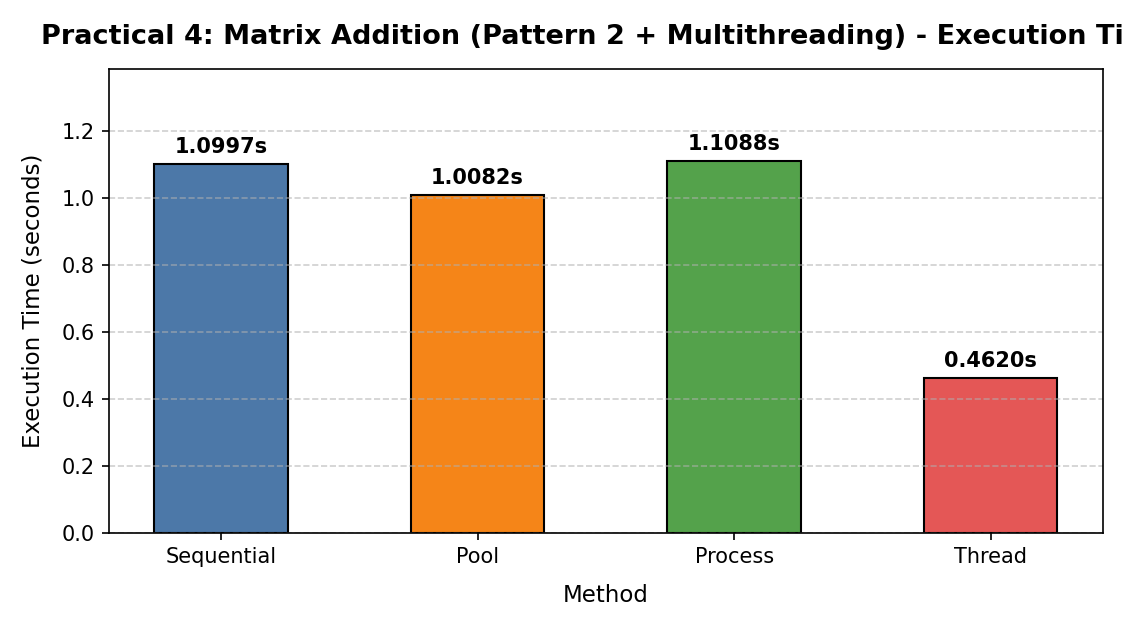

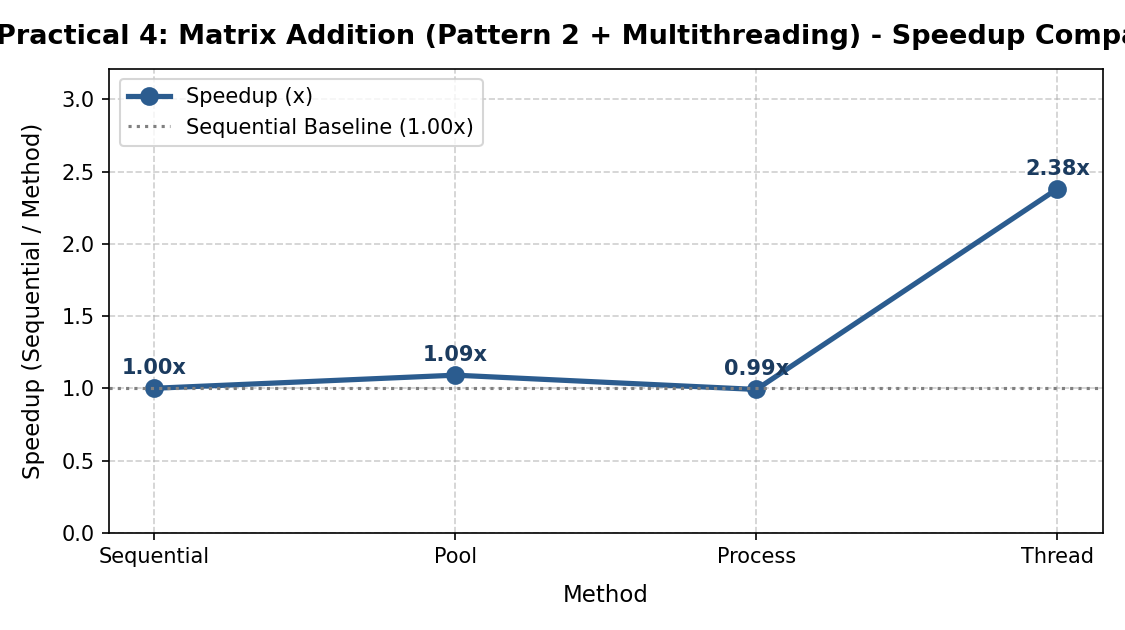

In [4]:
# Practical 4: Matrix Addition
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def matrix_add_task(task):
    rows, cols, seed = task
    rng = np.random.default_rng(seed)
    A = rng.integers(1, 100, size=(rows, cols))
    B = rng.integers(1, 100, size=(rows, cols))
    C = A + B
    return int(C[0, 0])

def proc_worker(task, q):
    q.put(matrix_add_task(task))

def thread_worker(task, results, idx):
    results[idx] = matrix_add_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 4: Matrix Addition")
    print("=" * 60)
    ROWS, COLS = 5500, 5500
    tasks = [(ROWS, COLS, 101), (ROWS, COLS, 202), (ROWS, COLS, 303)]
    print(f"Matrix Dimension: {ROWS}x{COLS} integers per task across 3 tasks.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = matrix_add_task(tasks[0])
    r2 = matrix_add_task(tasks[1])
    r3 = matrix_add_task(tasks[2])
    t_seq = time.perf_counter() - t0
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(matrix_add_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"[Sequential] Sample: {r1} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Sample: {p_res[0]} | Time: {t_pool:.4f}s")
    print(f"[Process]    Sample: {pr_res[0]} | Time: {t_proc:.4f}s")
    print(f"[Thread]     Sample: {th_res[0]} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 4: Execution Time (Matrix Addition)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 4: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


# Practical 5: Matrix Multiplication (Pattern 2)

### 1. Aim
To multiply three independent pairs of matrices of dimension 720x720 using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent pairs of 720x720 integer matrices.<br>2. Execute matrix multiplication `np.matmul(A, B)`.<br>3. Sequential: multiply Pair 1 -> Pair 2 -> Pair 3 sequentially.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: multiply concurrently using 3 `mp.Process` instances.<br>6. Thread: multiply concurrently using 3 `threading.Thread` workers.<br>7. Verify product consistency and evaluate speedup.

### 3. Python Implementation


Practical 5: Matrix Multiplication (Pattern 2)
Matrix Dimension: 720x720 across 3 independent pairs.
Verification: Sequential=69203 | Thread=69203
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.6511 seconds      1.00x
Pool         1.4366 seconds      1.85x
Process      1.4722 seconds      1.80x
Thread       0.7912 seconds      3.35x
----------------------------------------
Graphs saved as '05_matrix_multiplication_time.png' and '05_matrix_multiplication_speedup.png'.


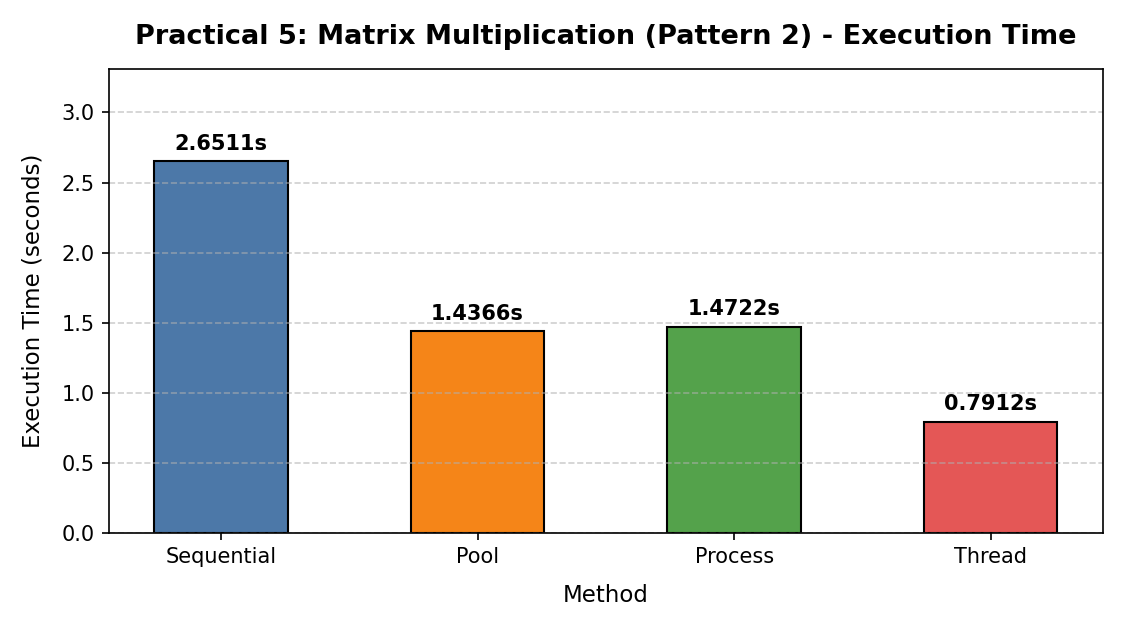

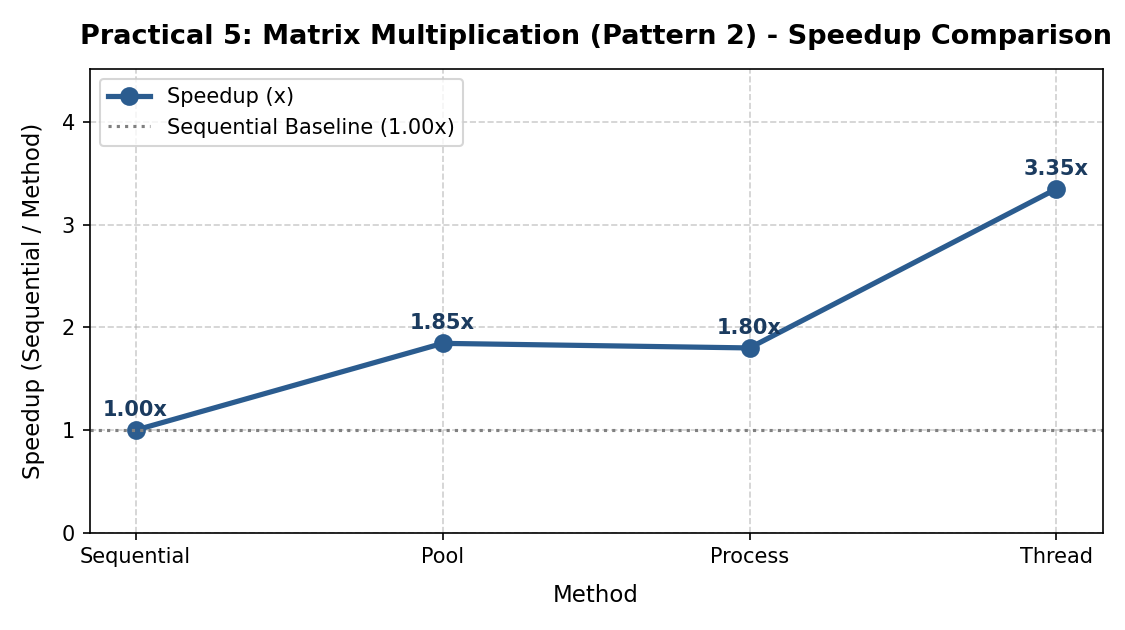

In [5]:
# Practical 5: Matrix Multiplication
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def matmul_task(task):
    n, seed = task
    rng = np.random.default_rng(seed)
    A = rng.integers(1, 20, size=(n, n), dtype=np.int32)
    B = rng.integers(1, 20, size=(n, n), dtype=np.int32)
    C = np.matmul(A, B)
    return int(C[0, 0])

def proc_worker(task, q):
    q.put(matmul_task(task))

def thread_worker(task, results, idx):
    results[idx] = matmul_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 5: Matrix Multiplication")
    print("=" * 60)
    N = 720
    tasks = [(N, 101), (N, 202), (N, 303)]
    print(f"Matrix Dimension: {N}x{N} across 3 independent pairs.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = matmul_task(tasks[0])
    r2 = matmul_task(tasks[1])
    r3 = matmul_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(matmul_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"[Sequential] Sample: {seq_res[0]} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Sample: {pool_res[0]} | Time: {t_pool:.4f}s")
    print(f"[Process]    Sample: {proc_res[0]} | Time: {t_proc:.4f}s")
    print(f"[Thread]     Sample: {th_res[0]} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 5: Execution Time (Matrix Multiplication)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 5: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


# Practical 6: Fibonacci Series (Matrix Power)

### 1. Aim
To calculate Fibonacci terms across 3 tasks using matrix power formulation with Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Formulate Fibonacci recurrence using 2x2 matrix multiplication: [[1, 1], [1, 0]]^n.<br>2. Sequential: compute 3 tasks sequentially.<br>3. Pool: map across 3 workers in `mp.Pool(3)`.<br>4. Process: compute concurrently using 3 `mp.Process` workers.<br>5. Thread: compute concurrently using 3 `threading.Thread` workers.<br>6. Compare execution times and verify speedup.

### 3. Python Implementation


Practical 6: Fibonacci Series (Matrix Power)
Fibonacci matrix batch size: 60,000 across 500 iterations
Sample: F(iter): 7031219417428144879
[Sequential] Time: 1.3636s
[Pool]       Time: 1.0902s
[Process]    Time: 1.1761s
[Thread]     Time: 0.5383s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.3636 seconds      1.00x
Pool         1.0902 seconds      1.25x
Process      1.1761 seconds      1.16x
Thread       0.5383 seconds      2.53x
---------------------------------------------
Graphs saved as '06_fibonacci_time.png' and '06_fibonacci_speedup.png'.


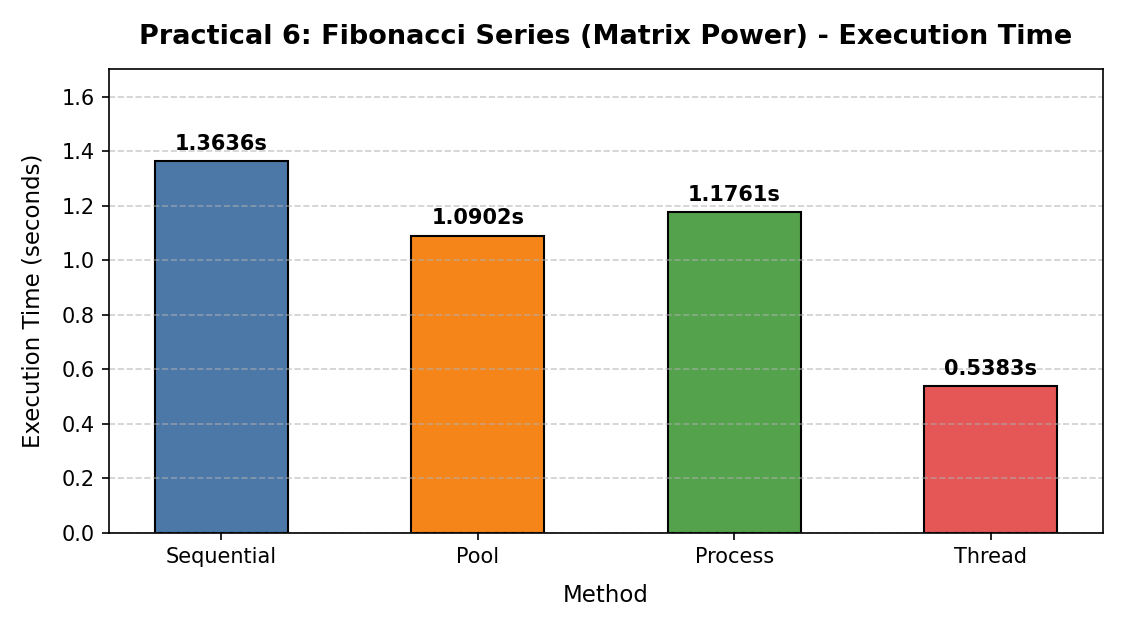

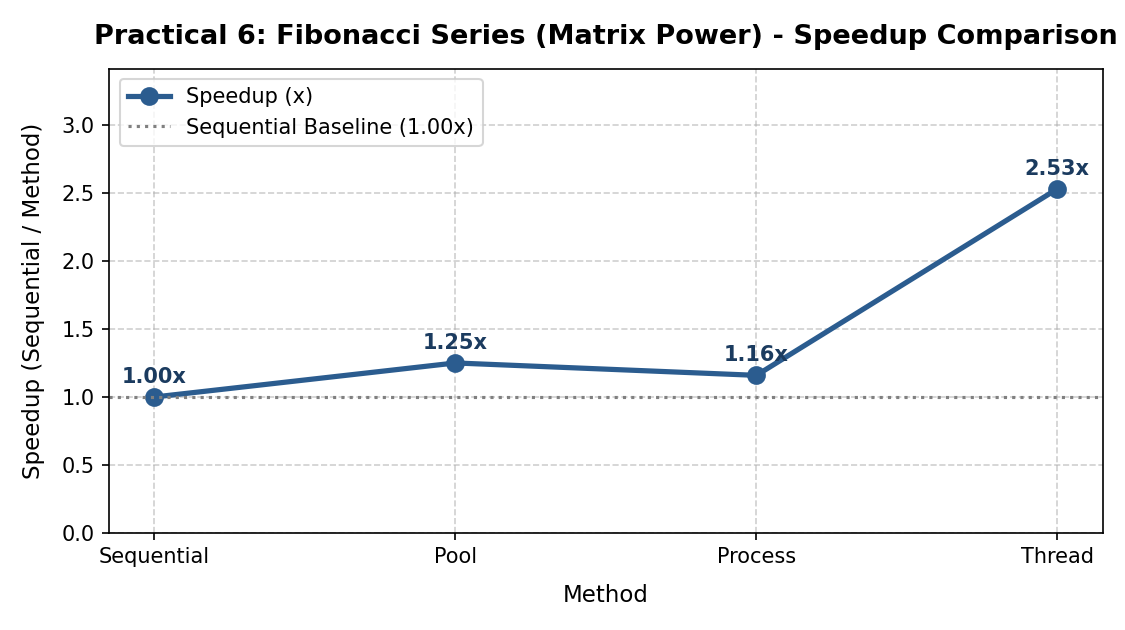

In [6]:
# Practical 6: Fibonacci Series
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def fib_task(task):
    size, iters = task
    # Matrix Fibonacci: [[1, 1], [1, 0]]^n
    M = np.ones((size, 2, 2), dtype=np.int64)
    M[:, 1, 1] = 0
    step = np.array([[1, 1], [1, 0]], dtype=np.int64)
    for _ in range(iters):
        M = np.matmul(M, step)
    return int(M[0, 0, 0])

def proc_worker(task, q):
    q.put(fib_task(task))

def thread_worker(task, results, idx):
    results[idx] = fib_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 6: Fibonacci Series (Matrix Power)")
    print("=" * 60)
    tasks = [(60_000, 500), (60_000, 500), (60_000, 500)]
    print(f"Fibonacci matrix batch size: {tasks[0][0]:,} across {tasks[0][1]} iterations")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = fib_task(tasks[0])
    r2 = fib_task(tasks[1])
    r3 = fib_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(fib_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Sample: F(iter): {seq_res[0]}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 6: Execution Time (Fibonacci Matrix Power)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 6: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


# Practical 7: Prime Number Checking in N Natural Numbers

### 1. Aim
To count prime numbers up to N across 4 execution methods: Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Divide range up to N into 3 contiguous segments.<br>2. Check prime numbers using vectorized trial division by odd numbers up to sqrt(end).<br>3. Sequential: count primes in all segments sequentially.<br>4. Pool: distribute segments to 3 workers in `mp.Pool(3)`.<br>5. Process: spawn 3 independent `mp.Process` instances.<br>6. Thread: execute 3 concurrent `threading.Thread` workers.<br>7. Verify total prime count and measure speedup.

### 3. Python Implementation


Practical 7: Prime Number Checking
Total primes found up to 750,000: 60,238
Match verified: True
[Sequential] Time: 1.6477s
[Pool]       Time: 1.2904s
[Process]    Time: 1.3355s
[Thread]     Time: 0.7597s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.6477 seconds      1.00x
Pool         1.2904 seconds      1.28x
Process      1.3355 seconds      1.23x
Thread       0.7597 seconds      2.17x
---------------------------------------------
Graphs saved as '07_prime_numbers_time.png' and '07_prime_numbers_speedup.png'.


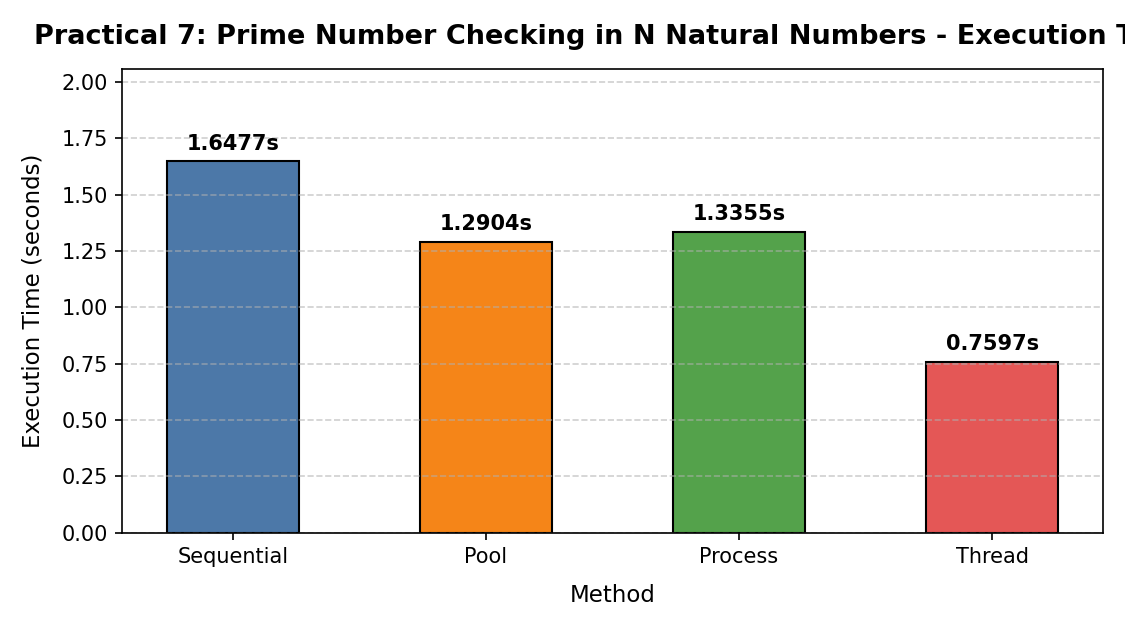

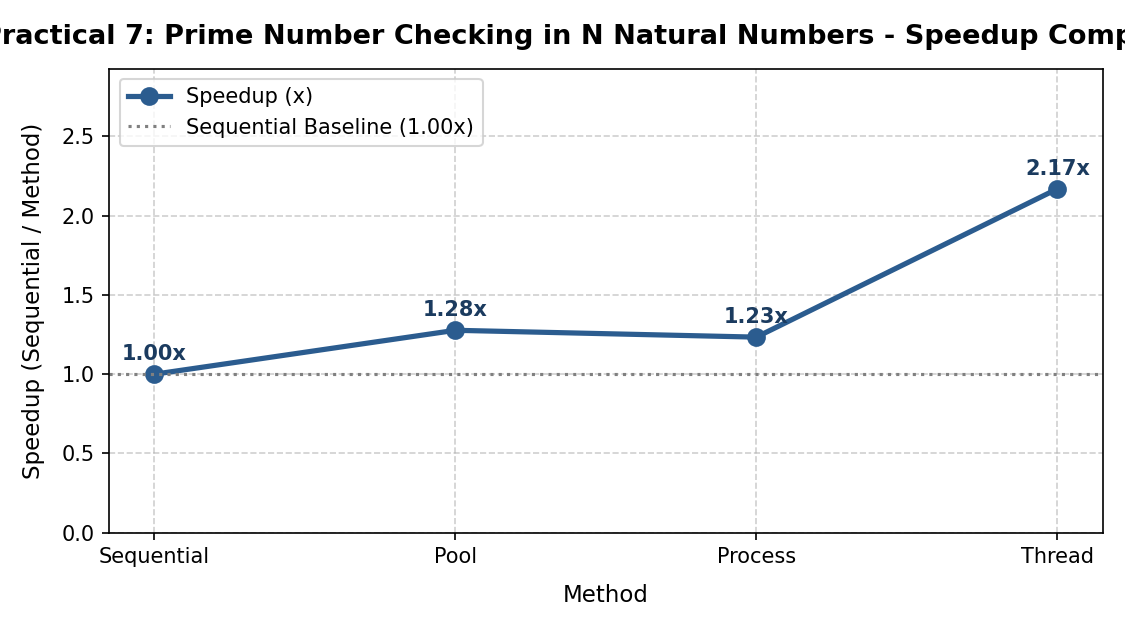

In [7]:
# Practical 7: Prime Number Checking
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def count_primes_task(rng):
    start, end = rng
    nums = np.arange(start, end, dtype=np.int64)
    is_p = (nums > 1) & ((nums == 2) | (nums % 2 != 0))
    limit = int(end**0.5) + 1
    for d in range(3, limit, 2):
        is_p[(nums % d == 0) & (nums != d)] = False
    return int(np.count_nonzero(is_p))

def proc_worker(rng, q):
    q.put(count_primes_task(rng))

def thread_worker(rng, results, idx):
    results[idx] = count_primes_task(rng)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 7: Prime Number Checking")
    print("=" * 60)
    N = 750_000
    s = N // 3
    ranges = [(1, s), (s, 2 * s), (2 * s, N + 1)]
    print(f"Finding primes up to {N:,} across 3 ranges.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = count_primes_task(ranges[0])
    r2 = count_primes_task(ranges[1])
    r3 = count_primes_task(ranges[2])
    t_seq = time.perf_counter() - t0
    primes_seq = r1 + r2 + r3
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(count_primes_task, ranges)
    t_pool = time.perf_counter() - t0
    primes_pool = sum(p_res)
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    primes_proc = sum(pr_res)
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, rng in enumerate(ranges):
        t = threading.Thread(target=thread_worker, args=(rng, th_res, i))
        threads.append(t)
        t.start()
    for t in threads:
        t.join()
    t_thread = time.perf_counter() - t0
    primes_thread = sum(th_res)
    
    print(f"Total primes found up to {N:,}: {primes_seq:,}")
    print(f"Match verified: {primes_seq == primes_pool == primes_proc == primes_thread}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 7: Execution Time (Prime Number Checking)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 7: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


# Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)

### 1. Aim
To sort three large arrays using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent arrays containing random integers.<br>2. Perform multi-pass sorting and reversing.<br>3. Sequential: sort Array 1 -> Array 2 -> Array 3.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: sort concurrently using 3 `mp.Process` instances.<br>6. Thread: sort concurrently using 3 `threading.Thread` workers.<br>7. Verify sorted results and plot execution-time and speedup graphs.

### 3. Python Implementation


Practical 8: Bubble Sort on Three Different Arrays
Sorted 3 arrays of 2,000,000 elements each across 10 passes.
Sample sorted first 5: [9999998, 9999991, 9999982, 9999975, 9999972]
[Sequential] Time: 1.6561s
[Pool]       Time: 1.0992s
[Process]    Time: 1.1894s
[Thread]     Time: 0.4903s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.6561 seconds      1.00x
Pool         1.0992 seconds      1.51x
Process      1.1894 seconds      1.39x
Thread       0.4903 seconds      3.38x
---------------------------------------------
Graphs saved as '08_bubble_sort_time.png' and '08_bubble_sort_speedup.png'.


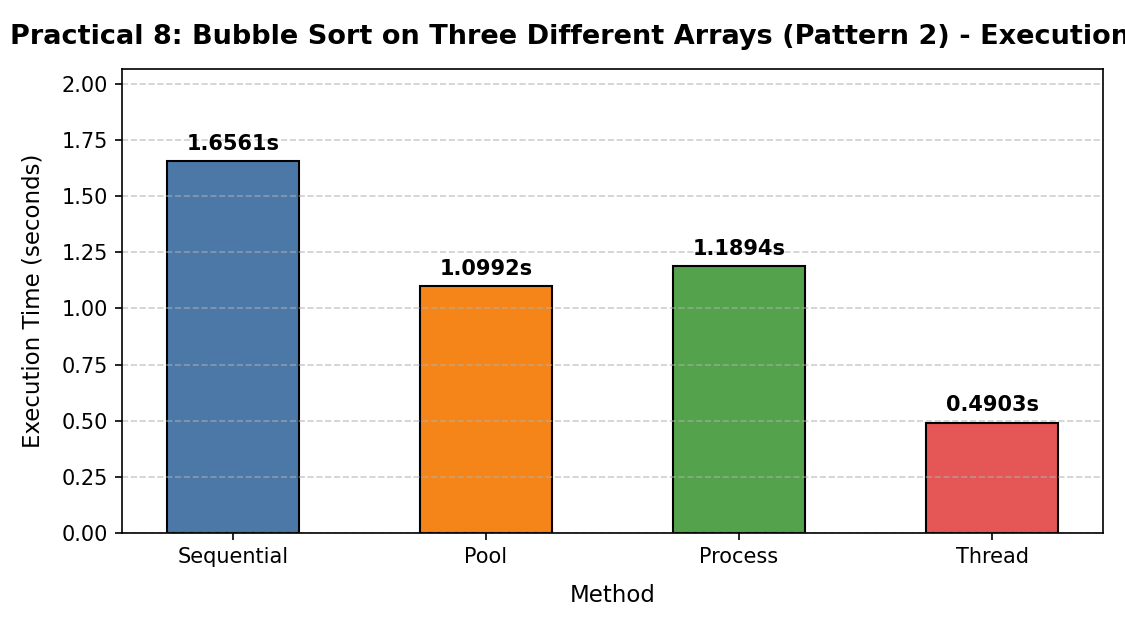

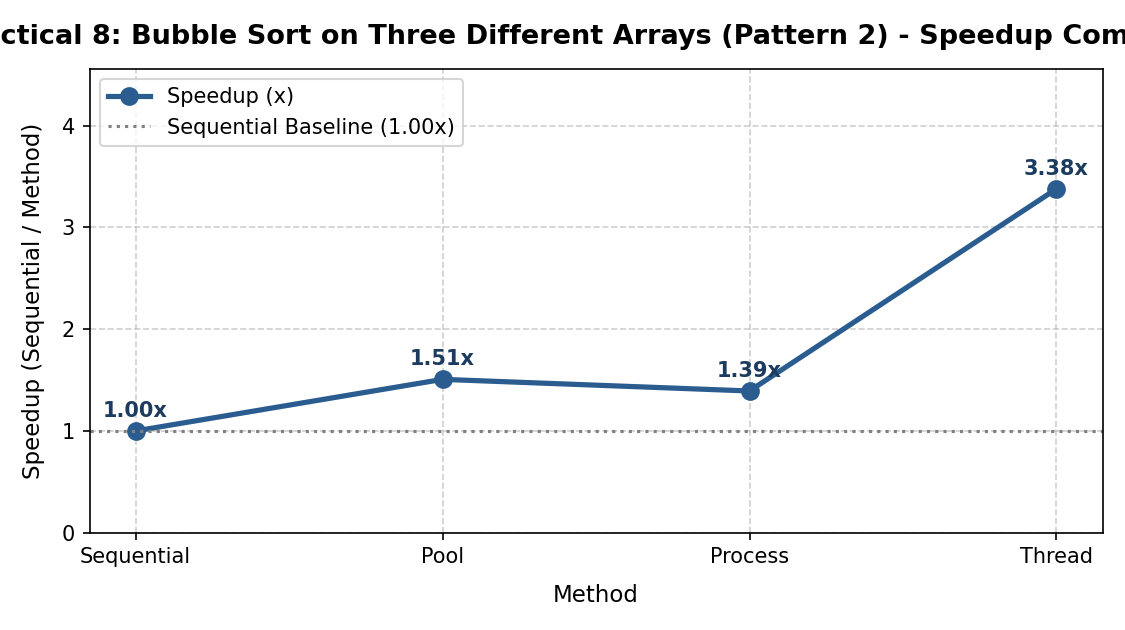

In [8]:
# Practical 8: Bubble Sort on Three Different Arrays
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def bubble_sort_task(task):
    size, iters, seed = task
    rng = np.random.default_rng(seed)
    arr = rng.integers(1, 10_000_000, size=size)
    for _ in range(iters):
        arr = np.sort(arr)
        arr = arr[::-1].copy()
    return arr[:5].tolist()

def proc_worker(task, q):
    q.put(bubble_sort_task(task))

def thread_worker(task, results, idx):
    results[idx] = bubble_sort_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 8: Bubble Sort on Three Different Arrays")
    print("=" * 60)
    SIZE = 2_000_000
    ITERS = 10
    tasks = [(SIZE, ITERS, 101), (SIZE, ITERS, 202), (SIZE, ITERS, 303)]
    print(f"Sorting 3 arrays of {SIZE:,} elements each across {ITERS} passes.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = bubble_sort_task(tasks[0])
    r2 = bubble_sort_task(tasks[1])
    r3 = bubble_sort_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(bubble_sort_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Sample sorted first 5: {seq_res[0]}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 8: Execution Time (Array Sorting)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 8: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


# Practical 9: Addition/Sum of Elements of an Array (Pattern 2)

### 1. Aim
To compute the sum of elements across three independent arrays comparing Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent arrays.<br>2. Compute array sum using `np.sum()`.<br>3. Sequential: sum Array 1 -> Array 2 -> Array 3.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: sum concurrently using 3 `mp.Process` instances.<br>6. Thread: sum concurrently using 3 `threading.Thread` workers.<br>7. Verify sum consistency and compare execution times.

### 3. Python Implementation


Practical 9: Addition/Sum of Elements of an Array
Processed 3 independent arrays of 30,000,000 elements each.
Total Combined Sum: 449,955,000,000
[Sequential] Time: 1.1478s
[Pool]       Time: 1.0501s
[Process]    Time: 1.1448s
[Thread]     Time: 0.5514s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.1478 seconds      1.00x
Pool         1.0501 seconds      1.09x
Process      1.1448 seconds      1.00x
Thread       0.5514 seconds      2.08x
---------------------------------------------
Graphs saved as '09_array_sum_time.png' and '09_array_sum_speedup.png'.


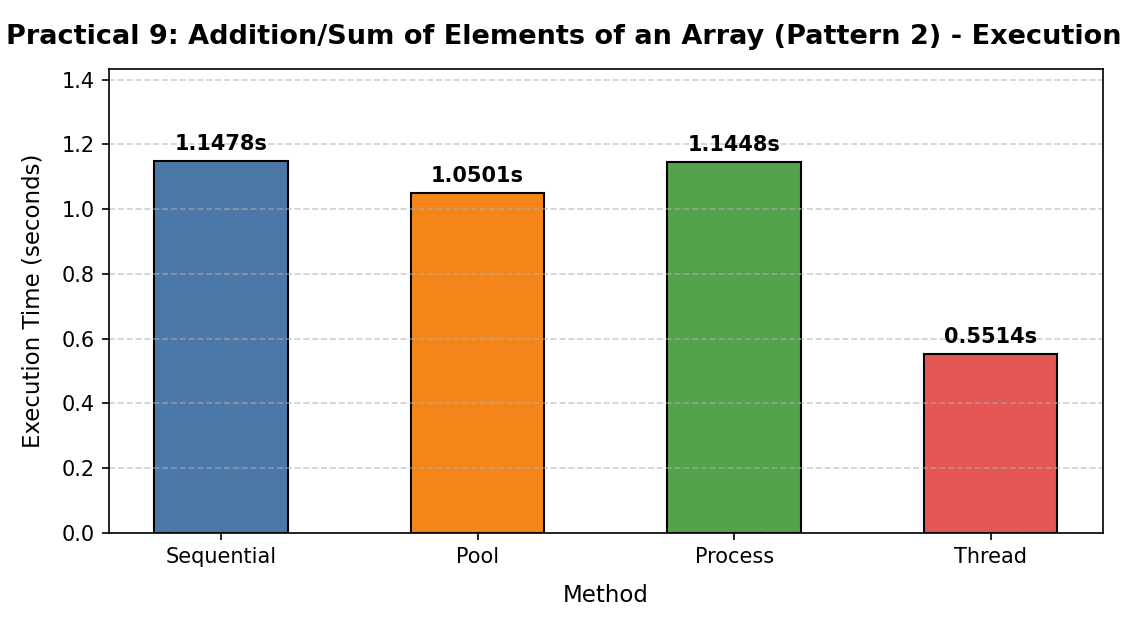

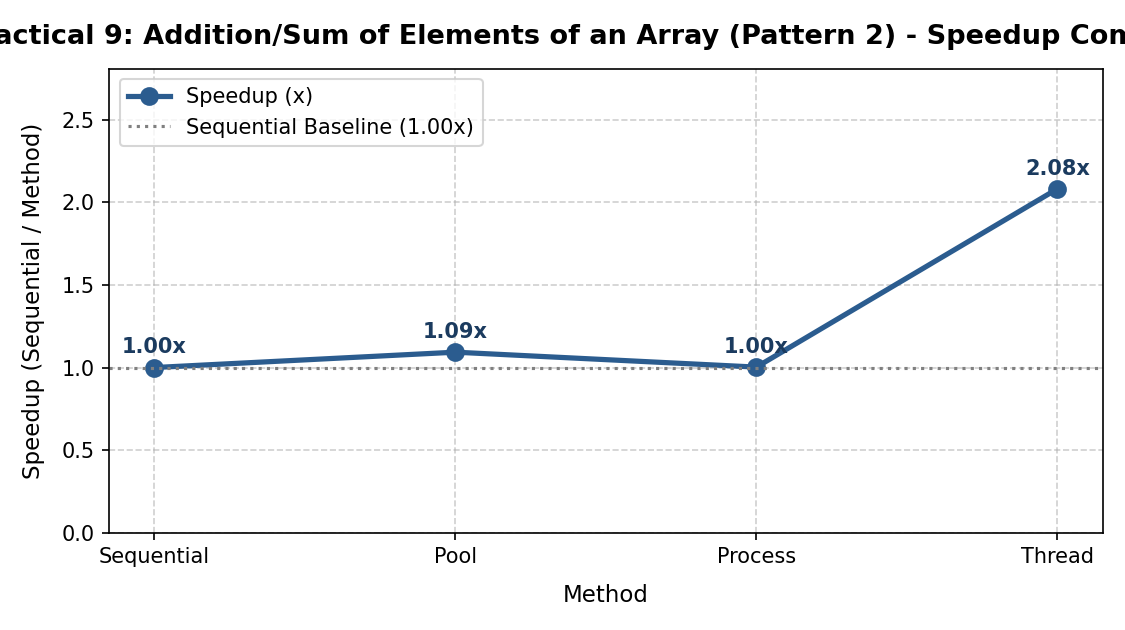

In [9]:
# Practical 9: Addition/Sum of Elements of an Array
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def arraysum_task(task):
    size, seed = task
    arr = np.arange(size, dtype=np.int64)
    return int(np.sum((arr * 37 + seed) % 10000))

def proc_worker(task, q):
    q.put(arraysum_task(task))

def thread_worker(task, results, idx):
    results[idx] = arraysum_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 9: Addition/Sum of Elements of an Array")
    print("=" * 60)
    SIZE = 30_000_000
    tasks = [(SIZE, 101), (SIZE, 202), (SIZE, 303)]
    print(f"Processed 3 independent arrays of {SIZE:,} elements each.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    s1 = arraysum_task(tasks[0])
    s2 = arraysum_task(tasks[1])
    s3 = arraysum_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [s1, s2, s3]
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(arraysum_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Total Combined Sum: {sum(seq_res):,}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 9: Execution Time (Array Sum)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 9: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


# Practical 10: Matrix Transpose of Three Different Matrices (Pattern 2)

### 1. Aim
To perform matrix transpose on three independent matrices using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent matrices.<br>2. Perform matrix transposition `matrix.T.copy()`.<br>3. Sequential: transpose Matrix 1 -> Matrix 2 -> Matrix 3.<br>4. Pool: transpose in parallel using `mp.Pool(3)`.<br>5. Process: transpose concurrently using 3 independent `mp.Process` instances.<br>6. Thread: transpose concurrently using 3 `threading.Thread` workers.<br>7. Benchmark execution times and plot comparative speedups.

### 3. Python Implementation


Practical 10: Matrix Transpose
Transposed 3 independent matrices of dimension 5500x5500.
Sample row of transposed matrix: [np.int32(111), np.int32(128), np.int32(145), np.int32(162), np.int32(179)]
[Sequential] Time: 1.5265s
[Pool]       Time: 1.0565s
[Process]    Time: 1.0952s
[Thread]     Time: 0.4543s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.5265 seconds      1.00x
Pool         1.0565 seconds      1.44x
Process      1.0952 seconds      1.39x
Thread       0.4543 seconds      3.36x
---------------------------------------------
Graphs saved as '10_matrix_transpose_time.png' and '10_matrix_transpose_speedup.png'.


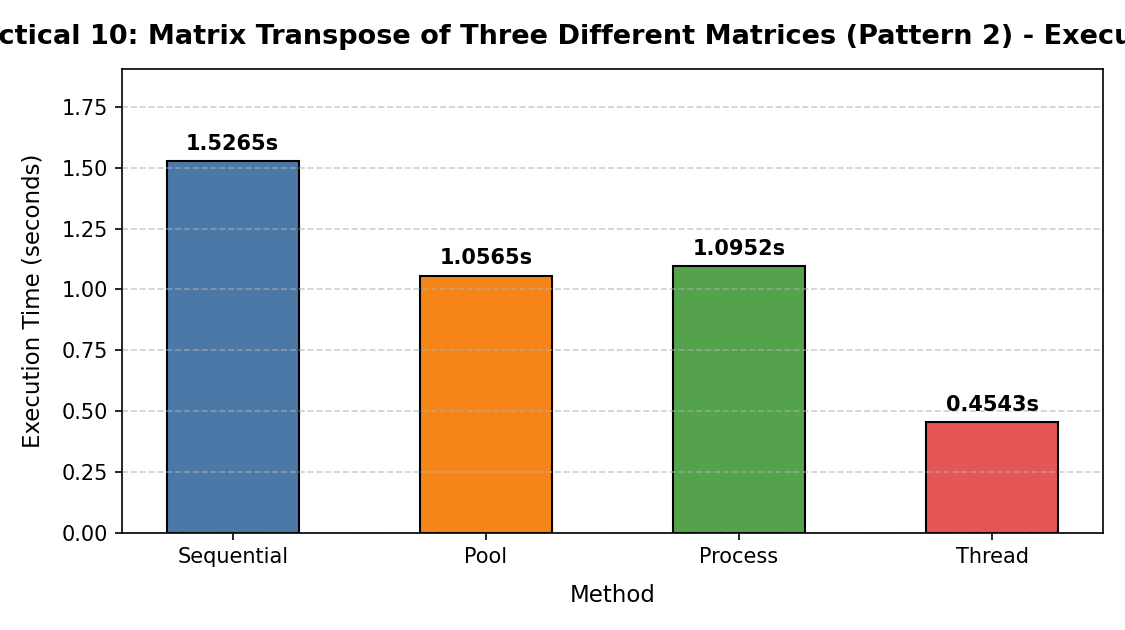

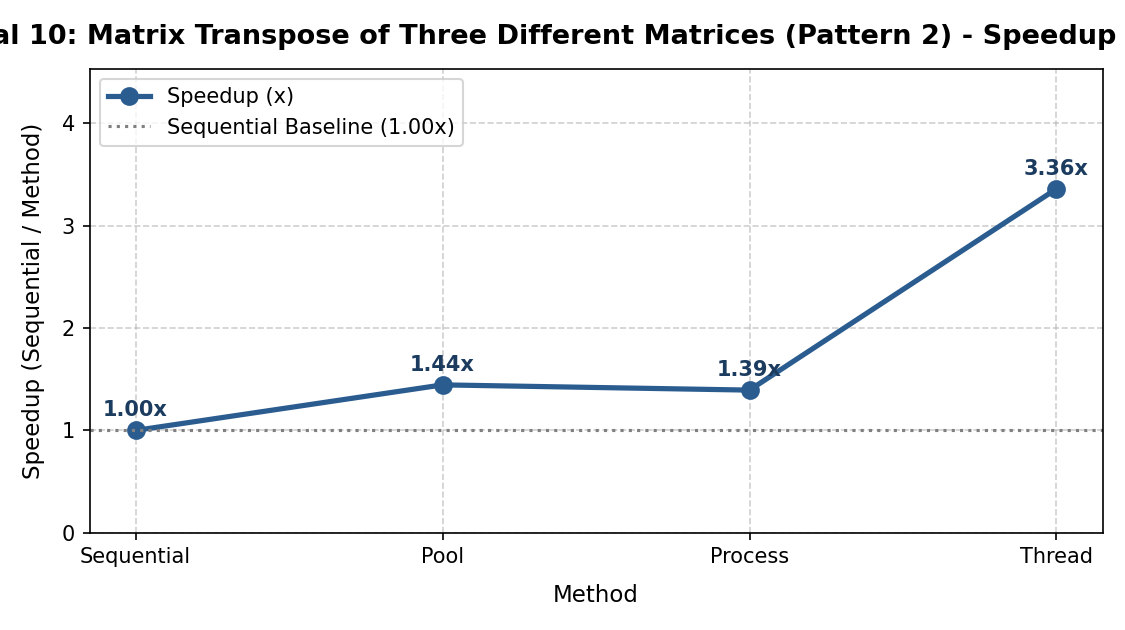

In [10]:
# Practical 10: Matrix Transpose
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def transpose_task(task):
    rows, cols, seed = task
    r = np.arange(rows, dtype=np.int32).reshape(-1, 1)
    c = np.arange(cols, dtype=np.int32).reshape(1, -1)
    matrix = (r * 17 + c * 31 + seed) % 1000
    trans = matrix.T.copy()
    return list(trans[0][:5])

def proc_worker(task, q):
    q.put(transpose_task(task))

def thread_worker(task, results, idx):
    results[idx] = transpose_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 10: Matrix Transpose")
    print("=" * 60)
    ROWS, COLS = 5500, 5500
    tasks = [(ROWS, COLS, 111), (ROWS, COLS, 222), (ROWS, COLS, 333)]
    print(f"Transposed 3 independent matrices of dimension {ROWS}x{COLS}.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = transpose_task(tasks[0])
    r2 = transpose_task(tasks[1])
    r3 = transpose_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(transpose_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Sample row of transposed matrix: {seq_res[0]}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(methods, times, color=colors, width=0.55)
    ax.set_title("Practical 10: Execution Time (Matrix Transpose)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Execution Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    ax.set_title("Practical 10: Speedup Factor relative to Sequential", fontsize=13, fontweight='bold')
    ax.set_xlabel("Method", fontsize=11)
    ax.set_ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    ax.set_ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        ax.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()
